In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sn

In [2]:
from sklearn.model_selection import train_test_split

In [3]:
train = pd.read_csv("/kaggle/input/competitions/titanic/train.csv")
test = pd.read_csv("/kaggle/input/competitions/titanic/test.csv")

In [4]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
train.shape

(891, 12)

In [6]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
target = "Survived"
x = train.drop(columns = [target])
y = train[target]

<function matplotlib.pyplot.show(close=None, block=None)>

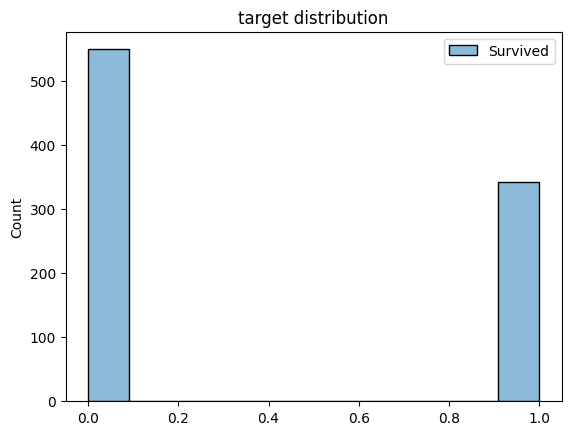

In [8]:
sn.histplot(train[["Survived"]])
plt.title("target distribution")
plt.savefig("target distribution.png")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

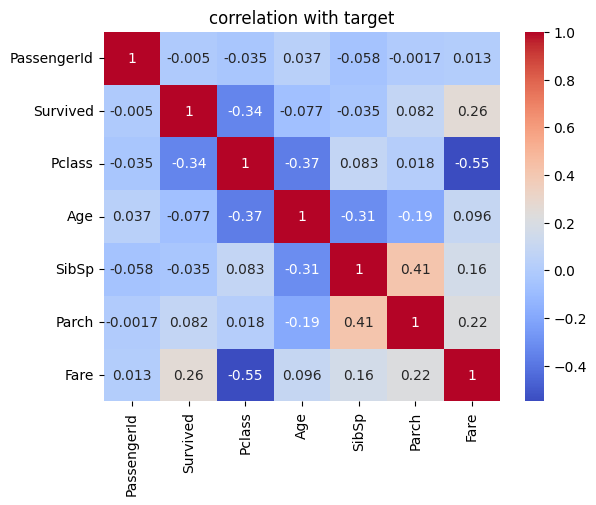

In [9]:
corr_matrix = train.corr(numeric_only=True)
sn.heatmap(corr_matrix,annot = True,cmap = "coolwarm" )
plt.title("correlation with target")
plt.show

In [10]:
drop_data = ["PassengerId","Name", "Ticket"]

In [11]:
train = train.drop(columns=drop_data)

In [12]:
train.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,male,22.0,1,0,7.2500,NaN,S
1,1,1,female,38.0,1,0,71.2833,C85,C
2,1,3,female,26.0,0,0,7.9250,NaN,S
3,1,1,female,35.0,1,0,53.1000,C123,S
4,0,3,male,35.0,0,0,8.0500,NaN,S


In [13]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size = 0.2, random_state  = 42)
print(len(x_train),len(x_test),len(y_train),len(y_test))

712 179 712 179


In [14]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Cabin     204 non-null    object 
 8   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(3)
memory usage: 62.8+ KB


In [15]:
nominal_features = ["Sex","Cabin","Embarked"]
numerical_features = x_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

In [17]:
num_trans = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])

In [18]:
nom_trans = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

In [19]:
preprocessor = ColumnTransformer(transformers = [
    ("numerical_features",num_trans, numerical_features),
    ("nominal_features",nom_trans,nominal_features)
])

In [20]:
from sklearn.ensemble import ExtraTreesClassifier,RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [21]:
cls = Pipeline(steps=[
    ("preprocessor",preprocessor),
    ("model",ExtraTreesClassifier())
])

In [22]:
param = {
    "model__n_estimators": [100,250,350,400],
    "model__max_depth": [4, 5, 6, 8],
    "model__min_samples_leaf": [2, 3, 5],
    "model__max_features": ["sqrt", "log2"],
}

In [23]:
run = GridSearchCV(cls, param_grid=param, scoring="accuracy", cv=6, verbose=2, n_jobs=8)

In [24]:
run.fit(x_train,y_train)

Fitting 6 folds for each of 96 candidates, totalling 576 fits
[CV] END model__max_depth=4, model__max_features=sqrt, model__min_samples_leaf=2, model__n_estimators=100; total time=   0.6s
[CV] END model__max_depth=4, model__max_features=sqrt, model__min_samples_leaf=2, model__n_estimators=250; total time=   1.2s
[CV] END model__max_depth=4, model__max_features=sqrt, model__min_samples_leaf=2, model__n_estimators=400; total time=   2.0s
[CV] END model__max_depth=4, model__max_features=sqrt, model__min_samples_leaf=3, model__n_estimators=100; total time=   0.6s
[CV] END model__max_depth=4, model__max_features=sqrt, model__min_samples_leaf=3, model__n_estimators=250; total time=   1.3s
[CV] END model__max_depth=4, model__max_features=sqrt, model__min_samples_leaf=3, model__n_estimators=350; total time=   1.8s
[CV] END model__max_depth=4, model__max_features=sqrt, model__min_samples_leaf=5, model__n_estimators=100; total time=   0.6s
[CV] END model__max_depth=4, model__max_features=sqrt, m

GridSearchCV(cv=6,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('numerical_features',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['PassengerId',
                                                                          'Pclass',
                                                                          'Age',
                                                                          'SibSp',
                                                                          'Parch',
                                                                          'Fare']),
                                                                        ('nominal_features',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(fill_value='None',
                                                                                                        strategy='constant')),
                                                                                         ('encoder',
                                                                                          OneHotEncoder(handle_unknown='ignore',
                                                                                                        sparse_output=False))]),
                                                                         ['Sex',
                                                                          'Cabin',
                                                                          'Embarked'])])),
                                       ('model', ExtraTreesClassifier())]),
             n_jobs=8,
             param_grid={'model__max_depth': [4, 5, 6, 8],
                         'model__max_features': ['sqrt', 'log2'],
                         'model__min_samples_leaf': [2, 3, 5],
                         'model__n_estimators': [100, 250, 350, 400]},
             scoring='accuracy', verbose=2)

In [25]:
print(run.best_params_)
print(run.best_score_)

{'model__max_depth': 8, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 3, 'model__n_estimators': 350}
0.8173574514551584


In [26]:
from sklearn.metrics import classification_report

In [27]:
y_predict = run.predict(x_test)

In [28]:
print(classification_report(y_test,y_predict))

              precision    recall  f1-score   support

           0       0.78      0.91      0.84       105
           1       0.84      0.64      0.72        74

    accuracy                           0.80       179
   macro avg       0.81      0.77      0.78       179
weighted avg       0.80      0.80      0.79       179



In [29]:
test_pred = run.predict(test) 


In [30]:
submission = pd.DataFrame({"PassengerId": test["PassengerId"], "Survived": test_pred})
submission.to_csv("submission.csv", index=False)
print(submission.shape)

(418, 2)


In [31]:
submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
